# Tokenization

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 23.04.2024
- Date of Last Modification: 06.05.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import scgpt as scg
import squidpy as sq
import torch
from datasets import load_from_disk
from scipy.stats import spearmanr
from scgpt.model import TransformerModel
from scgpt.tokenizer.gene_tokenizer import GeneVocab
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from skmisc.loess import loess

from nichejepa import tokenizers
from nichejepa import utils

/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/aih/sebastian.birk/miniconda3/envs/nichejepa/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


### 1.2 Run Notebook Setup

In [3]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"
cell_gene_means_dictionary_file = "../datasets/cell_gene_means_dictionary.pkl"
cell_gene_reg_stds_dictionary_file = "../datasets/cell_gene_reg_stds_dictionary.pkl"
cell_gene_nzmedians_dictionary_file = "../datasets/cell_gene_nzmedians_dictionary.pkl"
neighborhood_gene_means_dictionary_file = "../datasets/neighborhood_gene_means_dictionary.pkl"
neighborhood_gene_reg_stds_dictionary_file = "../datasets/neighborhood_gene_reg_stds_dictionary.pkl"
neighborhood_gene_nzmedians_dictionary_file = "../datasets/neighborhood_gene_nzmedians_dictionary.pkl"
geneformer_token_dictionary_file = "../datasets/geneformer_token_dictionary.pkl"
nichejepa_token_dictionary_file = "../datasets/token_dictionary.pkl"

# dataset_cache_file = "../datasets/scgpt_gene_embeddings"

scgpt_model_dir = Path("../scgpt/pretrained_model")
scgpt_model_config_file = scgpt_model_dir / "args.json"
scgpt_model_file = scgpt_model_dir / "best_model.pt"
scgpt_vocab_file = scgpt_model_dir / "vocab.json"
scgpt_metadata_file = Path("../scgpt/metadata/gene_info.csv")

## 2. Tokenization

In [3]:
dataset_name = "nanostring_cosmx_human_brain"

### 2.1 Create Token Dictionary

In [7]:
# Load data
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}.h5ad")

In [ ]:
### Create token dict for nichejepa with cell and neighborhood tokens ###

# Load geneformer token dict to get protein-coding and miRNA genes
with open(geneformer_token_dictionary_file, "rb") as f:
    token_dict = pickle.load(f)

# Add cls token
def insert_at_index(d, index, key, value):
    items = list(d.items())
    items.insert(index, (key, value))
    new_d = dict(items)
    return new_d
token_dict = insert_at_index(token_dict, 2, "<cls_cell>", 2)
token_dict = insert_at_index(token_dict, 3, "<cls_neighborhood>", 3)

# Remove genes not in dataset
gene_list = adata.var["ensembl_id"].tolist()
token_dict_copy = token_dict.copy()
for token in token_dict_copy.keys():
    if "ENS" in token and token not in gene_list:
        del(token_dict[token])
del(token_dict_copy)

# Separate gene tokens into cell and neighborhood tokens
new_token_dict = {
    (key + "_cell" if "ENS" in key else key): value
    for value, key in enumerate(token_dict.keys())}
new_token_dict_copy = new_token_dict.copy()
i = 0
for key in new_token_dict_copy.keys():
    if "ENS" in key:
        new_token_dict[key.replace("cell", "neighborhood")] = len(new_token_dict_copy) + i
        i += 1
del(new_token_dict_copy)

# Write to disk
with open(nichejepa_token_dictionary_file, "wb") as file:
    pickle.dump(new_token_dict, file)

In [9]:
# Load vocab
with open(nichejepa_token_dictionary_file, "rb") as file:
    token_dict = pickle.load(file)

token_dict_reverse = {value: key for key, value in token_dict.items()}

In [ ]:
# NicheJEPA token dict
token_dict

In [ ]:
# First cell gene token
token_dict["ENSG00000000938_cell"]

In [ ]:
# First neighborhood gene token
token_dict["ENSG00000000938_neighborhood"]

### 2.2 Compute Normalization Factors for Gene Counts

Corpus means, regularized standard deviations, and non-zero medians are used depending on the 'norm_method' specified in the STRankTokenizer (check source code).

#### 2.2.1 Compute Corpus Means, Regularized Standard Deviations, and Non-zero Medians for Cell and Neighborhood Genes

In [22]:
for norm_factor in ["read_depth", "cell_area"]:
    # Load data
    adata = sc.read_h5ad(f"{st_data_silver_folder_path}/{dataset_name}.h5ad")

    # Filter cells that did not pass QC
    if "filter_pass" in adata.obs.columns:
        filter_pass_idx = np.where([filter_pass == 1 for filter_pass in adata.obs["filter_pass"]])[0]
    else:
        print(f"adata has no column 'filter_pass'; utilizing all cells.")
        filter_pass_idx = np.array([i for i in range(adata.shape[0])])
    adata = adata[filter_pass_idx]
    
    # Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
    sq.gr.spatial_neighbors(adata,
                            coord_type="generic",
                            spatial_key="spatial",
                            radius=55,
                            )
    
    # Add self loops to spatial neighborhood graph
    adata.obsp["spatial_connectivities"].setdiag(1)
        
    # Compute sum of counts across each cell's neighborhood to get neighborhood counts per cell
    adata.layers["X_neighborhood"] = np.array(adata.obsp["spatial_connectivities"].T @ adata.X)

    if norm_factor == "read_depth":
        # Normalize cell gene counts by read depth
        norm_counts = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000
    
        # Normalize neighborhood gene counts by read depth
        norm_counts_neighborhood = (adata.layers["X_neighborhood"] /
                                    adata.layers["X_neighborhood"].sum(1).reshape(-1, 1) *
                                    10000)
    elif norm_factor == "cell_area":
        # Normalize cell gene counts by cell area
        norm_counts = (adata.X / adata.obs["area"].values.reshape(-1, 1) *
                       np.mean(adata.obs["area"]))
    
        # Compute neighborhood area
        adata.obs["neighborhood_area"] = np.array(adata.obsp["spatial_connectivities"].T @ adata.obs["area"].values.reshape(-1, 1))  
    
        # Normalize neighborhood counts
        norm_counts_neighborhood = (adata.layers["X_neighborhood"] /
                                    adata.obs["neighborhood_area"].values.reshape(-1, 1) *
                                    np.mean(adata.obs["neighborhood_area"]))
        
    # Compute means, vars, and non-zero medians of
    # read-depth or cell-area normalized cell gene counts
    cell_gene_means = np.mean(norm_counts, axis=0)
    cell_gene_vars = np.var(norm_counts, axis=0)
    masked_data = np.ma.masked_equal(norm_counts, 0)
    cell_gene_nzmedians = np.ma.mean(masked_data, axis=0)
    cell_gene_nzmedians = cell_gene_nzmedians.filled(0)
    
    # Compute means, vars, and non-zero medians of
    # read-depth or cell-area normalized neighborhood gene counts
    neighborhood_gene_means = np.mean(norm_counts_neighborhood, axis=0)
    neighborhood_gene_vars = np.var(norm_counts_neighborhood, axis=0)
    masked_data_neighborhood = np.ma.masked_equal(norm_counts_neighborhood, 0)
    neighborhood_gene_nzmedians = np.ma.mean(masked_data_neighborhood, axis=0)
    neighborhood_gene_nzmedians = neighborhood_gene_nzmedians.filled(0)
    
    # Learn mean-variance relationships for cell and neighborhood genes respectively
    # to remove (only) expected variance based on mean to stabilize variances across genes.
    # Inspired by seurat scaling to determine highly variable genes
    # https://github.com/scverse/scanpy/blob/4642cf8e2e51b257371792cb4fcb9611c0a81123/scanpy/preprocessing/_highly_variable_genes.py#L26
    not_const_cell_genes = cell_gene_vars > 0
    cell_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
    y = np.log10(cell_gene_vars[not_const_cell_genes])
    x = np.log10(cell_gene_means[not_const_cell_genes])
    cell_gene_model = loess(x, y, span=0.3, degree=2)
    cell_gene_model.fit()
    cell_gene_est_log_vars[not_const_cell_genes] = cell_gene_model.outputs.fitted_values
    cell_gene_reg_stds = np.sqrt(10**cell_gene_est_log_vars)
    
    not_const_neighborhood_genes = neighborhood_gene_vars > 0
    neighborhood_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
    y = np.log10(neighborhood_gene_vars[not_const_neighborhood_genes])
    x = np.log10(neighborhood_gene_means[not_const_neighborhood_genes])
    neighborhood_gene_model = loess(x, y, span=0.3, degree=2)
    neighborhood_gene_model.fit()
    neighborhood_gene_est_log_vars[not_const_neighborhood_genes] = neighborhood_gene_model.outputs.fitted_values
    neighborhood_gene_reg_stds = np.sqrt(10**neighborhood_gene_est_log_vars)
    
    # Create norm factor dictionaries for tokenizer and store on disk
    cell_gene_means_dict = {}
    cell_gene_reg_stds_dict = {}
    cell_gene_nzmedians_dict = {}
    neighborhood_gene_means_dict = {}
    neighborhood_gene_reg_stds_dict = {}
    neighborhood_gene_nzmedians_dict = {}
    
    for (gene, cell_gene_mean, cell_gene_reg_std, cell_gene_nzmedian,
         neighborhood_gene_mean, neighborhood_gene_reg_std, neighborhood_gene_nzmedian) in zip(
            adata.var["ensembl_id"].values,
            cell_gene_means,
            cell_gene_reg_stds,
            cell_gene_nzmedians,
            neighborhood_gene_means,
            neighborhood_gene_reg_stds,
            neighborhood_gene_nzmedians):
        cell_gene_means_dict[gene] = cell_gene_mean
        cell_gene_reg_stds_dict[gene] = cell_gene_reg_std
        cell_gene_nzmedians_dict[gene] = cell_gene_nzmedian
        neighborhood_gene_means_dict[gene] = neighborhood_gene_mean
        neighborhood_gene_reg_stds_dict[gene] = neighborhood_gene_reg_std
        neighborhood_gene_nzmedians_dict[gene] = neighborhood_gene_nzmedian
    
    with open(cell_gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(cell_gene_means_dict, file)
    with open(cell_gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(cell_gene_reg_stds_dict, file)
    with open(cell_gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(cell_gene_nzmedians_dict, file)
    with open(neighborhood_gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(neighborhood_gene_means_dict, file)
    with open(neighborhood_gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(neighborhood_gene_reg_stds_dict, file)
    with open(neighborhood_gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"), "wb") as file:
        pickle.dump(neighborhood_gene_nzmedians_dict, file)

#### 2.2.2 Test Normalization

In [ ]:
# Keep only protein-coding and miRNA genes
vocab = list(token_dict.keys())
coding_miRNA_ids = [
    key.split("_")[0] for key in list(vocab) if "_cell" in key]
coding_miRNA_dict = dict(zip(coding_miRNA_ids, [True] * len(vocab)))
coding_miRNA_idx = np.where(
    [coding_miRNA_dict.get(gene_id, False) for gene_id in adata.var["ensembl_id"]])[0]
coding_miRNA_adata = adata[:, coding_miRNA_idx]

In [ ]:
# Load cell and neighborhood gene corpus means and vars
with open(cell_gene_means_dictionary_file, "rb") as f:
    cell_gene_means_dict = pickle.load(f)
with open(cell_gene_reg_stds_dictionary_file, "rb") as f:
    cell_gene_reg_stds_dict = pickle.load(f)
with open(neighborhood_gene_means_dictionary_file, "rb") as f:
    neighborhood_gene_means_dict = pickle.load(f)
with open(neighborhood_gene_reg_stds_dictionary_file, "rb") as f:
    neighborhood_gene_reg_stds_dict = pickle.load(f)

cell_gene_means = np.array(
    [cell_gene_means_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])
cell_gene_reg_stds = np.array(
    [cell_gene_reg_stds_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])
neighborhood_gene_means = np.array(
    [neighborhood_gene_means_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])
neighborhood_gene_reg_stds = np.array(
    [neighborhood_gene_reg_stds_dict[gene_id] for gene_id in adata.var["ensembl_id"][coding_miRNA_idx]])

In [ ]:
# Compute mean std normalized counts where std is expected std based on mean
read_depth_norm_counts = coding_miRNA_adata.X / coding_miRNA_adata.X.sum(1).reshape(-1, 1) * 10000
mean_std_norm_counts = (read_depth_norm_counts - cell_gene_means) / cell_gene_reg_stds

In [ ]:
read_depth_norm_counts_neighborhood = (
    coding_miRNA_adata.layers["counts_neighborhood"] /
    coding_miRNA_adata.layers["counts_neighborhood"].sum(1).reshape(-1, 1) * 10000)
mean_std_norm_counts_neighborhood = (
    read_depth_norm_counts_neighborhood - neighborhood_gene_means) / neighborhood_gene_reg_stds

### 2.3 Run Tokenizer

In [ ]:
# Tokenize data with different normalization methods
for norm_method in ["analytic_pearson_residuals",
                    "seurat_v3",
                    "mean",
                    "nzmedian",
                    "shifted_log"]:
    if norm_method == "analytic_pearson_residuals":
        output_file_prefix = f"{dataset_name}_{norm_method}"

        tk = tokenizers.STRankTokenizer(
            norm_method=norm_method,
            token_dictionary_file=nichejepa_token_dictionary_file,
            custom_attr_name_dict={"cell_type": "cell_types",
                                   "niche_type": "niche_types"})

        tk.tokenize_data(input_directory=st_data_silver_folder_path,
                         output_directory=st_data_gold_folder_path,
                         output_file_prefix=output_file_prefix)
        
    elif norm_method != "analytic_pearson_residuals":
        for norm_factor in ["read_depth",
                            "cell_area"]:
            output_file_prefix = f"{dataset_name}_{norm_factor}_{norm_method}"

            tk = tokenizers.STRankTokenizer(
                    norm_method=norm_method,
                    cell_gene_means_file=cell_gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    cell_gene_reg_stds_file=cell_gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    cell_gene_nzmedians_file=cell_gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    neighborhood_gene_means_file=neighborhood_gene_means_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    neighborhood_gene_reg_stds_file=neighborhood_gene_reg_stds_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    neighborhood_gene_nzmedians_file=neighborhood_gene_nzmedians_dictionary_file.replace("gene", f"gene_{norm_factor}"),
                    token_dictionary_file=nichejepa_token_dictionary_file,
                    custom_attr_name_dict={"cell_type": "cell_types",
                                           "niche_type": "niche_types"})
                
            tk.tokenize_data(input_directory=st_data_silver_folder_path,
                             output_directory=st_data_gold_folder_path,
                             output_file_prefix=output_file_prefix)

### 2.4 Evaluate Tokenizer

In [ ]:
# Load tokenized dataset
tokenized_data_folder_path = f"{st_data_gold_folder_path}/{dataset_name}.dataset"
dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)

In [ ]:
# Get cell and neighborhood gene token rankings
gene_token_ranking = np.array(dataset["input_ids"])
adata.obsm["cell_gene_token_ranking"] = gene_token_ranking[:, 1:1024]
adata.obsm["neighborhood_gene_token_ranking"] = gene_token_ranking[:, 1025:]

In [ ]:
# Validate
gene_idx = np.argmax(mean_std_norm_counts, axis=1)[0]
print(coding_miRNA_adata.var["ensembl_id"][gene_idx])
gene_token_idx = coding_miRNA_adata.obsm["cell_gene_token_ranking"][0][0]
print(token_dict_reverse[gene_token_idx])

gene_idx = np.argmax(mean_std_norm_counts_neighborhood, axis=1)[0]
print(coding_miRNA_adata.var["ensembl_id"][gene_idx])
gene_token_idx = coding_miRNA_adata.obsm["neighborhood_gene_token_ranking"][0][0]
print(token_dict_reverse[gene_token_idx])

#### 2.4.1 Cell Type Classification

Task: cell type classification using scGPT embedded top ranked genes.

In [6]:
### Get scGPT gene embeddings for each gene Ensembl id ###

# Set config
pad_token = "<pad>"
special_tokens = [pad_token, "<cls>", "<eoc>"]
pad_value = -2
n_input_bins = 51

# Get vocab
scgpt_vocab = GeneVocab.from_file(scgpt_vocab_file)
for s in special_tokens:
    if s not in scgpt_vocab:
        scgpt_vocab.append_token(s)

# Retrieve model parameters from config files
with open(scgpt_model_config_file, "r") as f:
    model_configs = json.load(f)
print(f"Resume model from {scgpt_model_file}, the model args will override the "
      f"config {scgpt_model_config_file}.")
embsize = model_configs["embsize"]
nhead = model_configs["nheads"]
d_hid = model_configs["d_hid"]
nlayers = model_configs["nlayers"]
n_layers_cls = model_configs["n_layers_cls"]

# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ntokens = len(scgpt_vocab)  # size of vocabulary
model = TransformerModel(ntokens,
                         embsize,
                         nhead,
                         d_hid,
                         nlayers,
                         vocab=scgpt_vocab,
                         pad_value=pad_value,
                         n_input_bins=n_input_bins,)

try:
    model.load_state_dict(torch.load(scgpt_model_file))
    print(f"Loading all model params from {scgpt_model_file}")
except:
    model_dict = model.state_dict()
    pretrained_dict = torch.load(scgpt_model_file)
    pretrained_dict = {k: v
                       for k, v in pretrained_dict.items()
                       if k in model_dict and v.shape == model_dict[k].shape}
    for k, v in pretrained_dict.items():
        print(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model.to(device)

# Create mapping from Ensembl id to scGPT token id
gene2idx = scgpt_vocab.get_stoi()

metadata_df = pd.read_csv(scgpt_metadata_file)

ensemblid_mapping = dict(zip(metadata_df["feature_name"], metadata_df["feature_id"]))
ensemblid2idx = {ensemblid_mapping[k]: v for k, v in gene2idx.items() if k in ensemblid_mapping}

# Retrieve the data-independent gene embeddings from scGPT
gene_ids = np.array([id for id in ensemblid2idx.values()])
gene_embeddings = model.encoder(torch.tensor(gene_ids, dtype=torch.long).to(device))
gene_embeddings = gene_embeddings.detach().cpu().numpy()

# Store gene embeddings with Ensembl id
emsemblid_embedding_mapping = {}
for i, (key, val) in enumerate(ensemblid2idx.items()):
    emsemblid_embedding_mapping[key] = gene_embeddings[i, :]

Resume model from ../scgpt/pretrained_model/best_model.pt, the model args will override the config ../scgpt/pretrained_model/args.json.
Loading params encoder.embedding.weight with shape torch.Size([60697, 512])
Loading params encoder.enc_norm.weight with shape torch.Size([512])
Loading params encoder.enc_norm.bias with shape torch.Size([512])
Loading params value_encoder.linear1.weight with shape torch.Size([512, 1])
Loading params value_encoder.linear1.bias with shape torch.Size([512])
Loading params value_encoder.linear2.weight with shape torch.Size([512, 512])
Loading params value_encoder.linear2.bias with shape torch.Size([512])
Loading params value_encoder.norm.weight with shape torch.Size([512])
Loading params value_encoder.norm.bias with shape torch.Size([512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.weight with shape torch.Size([512, 512])
Loading params transformer_encoder.layers.0.self_attn.out_proj.bias with shape torch.Size([512])
Loading params tran

In [7]:
# Get scgpt gene embeddings for NicheJEPA input token ids
def get_scgpt_gene_embeddings(example):
    example["top_10_cell_tokens"] = [
        token_dict_reverse[token_id].replace("_cell", "")
        for token_id in example["input_ids"][1:11]]
    example["top_10_neighborhood_tokens"] = [
        token_dict_reverse[token_id].replace("_neighborhood", "")
        for token_id in example["input_ids"][1025:1035]]
    #example["top_10_cell_gene_embeddings_scgpt"] = [
    #    emsemblid_embedding_mapping.get(token, np.zeros(512, dtype=np.float32))
    #    for token in example["top_10_cell_tokens"]]                     
    return example

In [ ]:
scores = []

for norm_method in ["analytic_pearson_residuals",
                    "seurat_v3",
                    "mean",
                    "shifted_log"]:
    if norm_method == "analytic_pearson_residuals":
        tokenizer = f"{norm_method}"
    if norm_method != "analytic_pearson_residuals":
        norm_factor = "read_depth" # "cell_area"
        tokenizer = f"{norm_factor}_{norm_method}"
    
    output_file_prefix = f"{dataset_name}_{tokenizer}"
    tokenized_data_folder_path = f"{st_data_gold_folder_path}/{output_file_prefix}.dataset"
    dataset = load_from_disk(tokenized_data_folder_path, keep_in_memory=True)
    dataset = dataset.map(get_scgpt_gene_embeddings, #cache_file_name=dataset_cache_file
                         )

    X_cell = np.array(
        [[emsemblid_embedding_mapping[token] for token in sequence] for
         sequence in dataset["top_10_cell_tokens"]])
    X_cell = X_cell.reshape(X_cell.shape[0], -1)

    X_neighborhood = np.array(
        [[emsemblid_embedding_mapping[token] for token in sequence] for
         sequence in dataset["top_10_neighborhood_tokens"]])
    X_neighborhood = X_neighborhood.reshape(X_neighborhood.shape[0], -1)

    label_encoder_cell_types = LabelEncoder()
    Y_cell_types = np.array(
        label_encoder_cell_types.fit_transform(dataset["cell_types"]))
    label_encoder_niche_types = LabelEncoder()
    Y_niche_types = np.array(
        label_encoder_niche_types.fit_transform(dataset["niche_types"]))

    indices = np.arange(X_cell.shape[0])
    np.random.shuffle(indices)
    num_train = int(0.8 * len(indices))
    train_indices = indices[:num_train]
    test_indices = indices[num_train:]
    X_cell_train = X_cell[train_indices]
    X_cell_test = X_cell[test_indices]
    X_neighborhood_train = X_neighborhood[train_indices]
    X_neighborhood_test = X_neighborhood[test_indices]
    Y_cell_types_train = Y_cell_types[train_indices]
    Y_cell_types_test = Y_cell_types[test_indices]
    Y_niche_types_train = Y_niche_types[train_indices]
    Y_niche_types_test = Y_niche_types[test_indices]

    for token_type in ["cell", "neighborhood"]:
        for clf_task in ["cell_type", "niche_type"]:
            if token_type == "cell":
                X = X_cell
            else:
                X = X_neighborhood
            if clf_task == "cell_type":
                Y = Y_cell_types
            else:
                Y = Y_niche_types
            X_train = X[train_indices]
            X_test = X[test_indices]
            Y_train = Y[train_indices]
            Y_test = Y[test_indices]
            
            lr_clf = LogisticRegression(max_iter=1000)
            lr_clf.fit(X_train, Y_train)
            train_score = lr_clf.score(X_train, Y_train)
            test_score = lr_clf.score(X_test, Y_test)
            scores.append({"tokenizer": tokenizer,
                           "token_type": token_type,
                           "clf_task": clf_task,
                           "clf_category": "train",
                           "score": train_score})
            scores.append({"tokenizer": tokenizer,
                           "token_type": token_type,
                           "clf_task": clf_task,
                           "clf_category": "test",
                           "score": test_score})

            scores_df = pd.DataFrame(scores)
            scores_df.to_csv(f"../datasets/temp/{dataset_name}/clf_scores.csv", index=False)

Map:   0%|          | 0/188686 [00:00<?, ? examples/s]

In [22]:
scores_df = pd.read_csv(f"../datasets/temp/{dataset_name}/clf_scores.csv")

In [29]:
scores_df = scores_df[scores_df['clf_category'] == 'test']

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_3873512/846503532.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


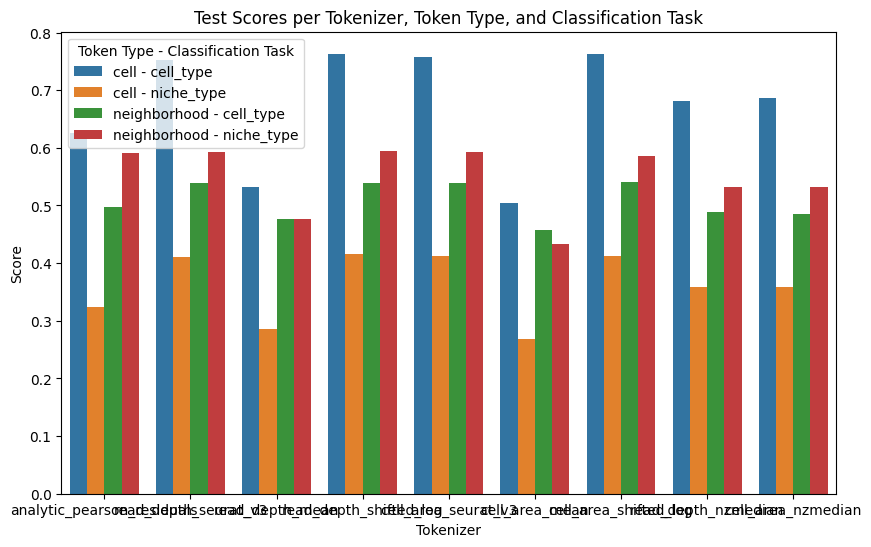

In [35]:
# Initialize the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a bar plot with hue representing a combination of token_type and clf_task
sns.barplot(
    data=scores_df, 
    x='tokenizer', 
    y='score', 
    hue=scores_df['token_type'] + ' - ' + scores_df['clf_task'], 
    ci=None
)

# Add some customizations
plt.xlabel('Tokenizer')
plt.ylabel('Score')
plt.title('Test Scores per Tokenizer, Token Type, and Classification Task')
plt.legend(title='Token Type - Classification Task')

# Show the plot
plt.show()

In [38]:
test_df = scores_df

/tmp/ipykernel_3873512/1702477414.py:9: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  bar_plot = sns.barplot(


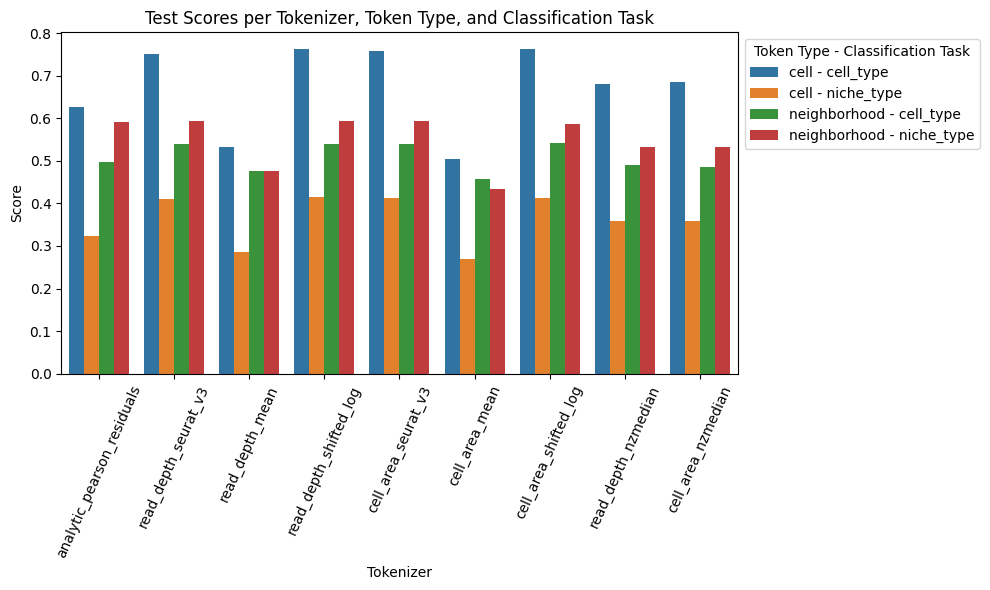

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a bar plot with hue representing a combination of token_type and clf_task
bar_plot = sns.barplot(
    data=test_df, 
    x='tokenizer', 
    y='score', 
    hue=test_df['token_type'] + ' - ' + test_df['clf_task'], 
    ci=None
)

# Customizations
plt.xlabel('Tokenizer')
plt.ylabel('Score')
plt.title('Test Scores per Tokenizer, Token Type, and Classification Task')
plt.xticks(rotation=66)  # Rotate x-axis labels for better readability
plt.legend(title='Token Type - Classification Task', loc='upper left', bbox_to_anchor=(1, 1))  # Move legend outside of plot

# Tight layout often provides better subplot spacing
plt.tight_layout()

# Show the plot
plt.show()

/tmp/ipykernel_3873512/3287080837.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  bar_plot = sns.barplot(


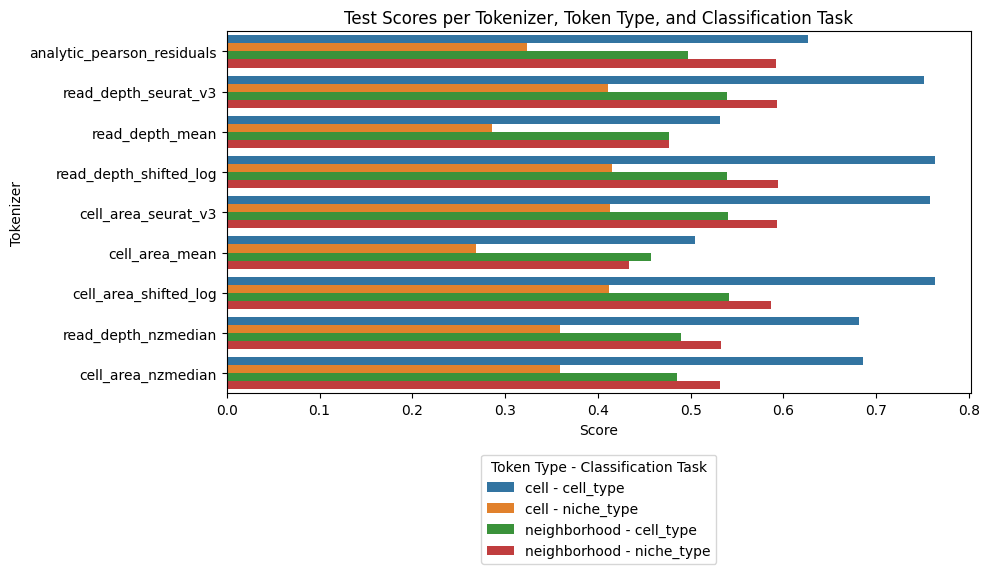

In [44]:
# Initialize the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a horizontal bar plot with hue representing a combination of token_type and clf_task
bar_plot = sns.barplot(
    data=test_df, 
    y='tokenizer',  # Set tokenizer as the main categorical variable for the y-axis
    x='score',      # Set score as the numerical value for the x-axis
    hue=test_df['token_type'] + ' - ' + test_df['clf_task'], 
    ci=None
)

# Customizations
plt.ylabel('Tokenizer')  # Now labeling the y-axis as 'Tokenizer'
plt.xlabel('Score')      # Now labeling the x-axis as 'Score'
plt.title('Test Scores per Tokenizer, Token Type, and Classification Task')

# Adjusting legend
plt.legend(title='Token Type - Classification Task', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=1)

# Tight layout for better spacing
plt.tight_layout()

# Show the plot
plt.show()

#### 2.4.2 Neighborhood Ranking

In [ ]:
# Normalize counts as per https://www.sc-best-practices.org/preprocessing_visualization/normalization.html
sc.pp.log1p(adata)

In [ ]:
# Compute spatial autocorrelation score
sq.gr.spatial_autocorr(adata)
if "I" in adata.var.columns:
    del(adata.var["I"])
adata.var = adata.var.join(adata.uns["moranI"][["I"]], how="left")

In [ ]:
adata.X

In [ ]:
sq.pl.spatial_scatter(adata, color="CNP", shape=None) 

In [ ]:
sq.pl.spatial_scatter(adata, layer="counts", color="MBP", shape=None) 

In [ ]:
sq.pl.spatial_scatter(adata, layer="counts_neighborhood", color="MBP", shape=None) 

In [ ]:
adata.var["neigborhood_gene_rank_sums"].sort_values(ascending=False)

In [ ]:
# Sum up ranks for each neighborhood gene token
neighborhood_gene_token_rank_sums = {}

for i, row in enumerate(adata.obsm["neighborhood_gene_token_ranking"]):
    for rank, token in enumerate(row[:10]):
        if token in neighborhood_gene_token_rank_sums:
            neighborhood_gene_token_rank_sums[token] += (10 - rank)
        else:
            neighborhood_gene_token_rank_sums[token] = (10 - rank)

# Replace gene token by gene ensembl id
neighborhood_gene_rank_sums = {}

for key, value in token_dict.items():
    if value in neighborhood_gene_token_rank_sums:
        neighborhood_gene_rank_sums[key.replace("_neighborhood", "")] = neighborhood_gene_token_rank_sums[value]

neighborhood_gene_rank_file = f"../datasets/temp/{dataset_name}/neighborhood_gene_rank_sums.pkl"

with open(neighborhood_gene_rank_file, "wb") as file:
    pickle.dump(neighborhood_gene_rank_sums, file)

In [ ]:
# Sum up ranks for each cell gene token
cell_gene_token_rank_sums = {}

for i, row in enumerate(adata.obsm["cell_gene_token_ranking"]):
    for rank, token in enumerate(row[:10]):
        if token in cell_gene_token_rank_sums:
            cell_gene_token_rank_sums[token] += (10 - rank)
        else:
            cell_gene_token_rank_sums[token] = (10 - rank)

# Replace gene token by gene ensembl id
cell_gene_rank_sums = {}

for key, value in token_dict.items():
    if value in cell_gene_token_rank_sums:
        cell_gene_rank_sums[key.replace("_cell", "")] = cell_gene_token_rank_sums[value]

cell_gene_rank_file = f"../datasets/temp/{dataset_name}/cell_gene_rank_sums.pkl"

with open(cell_gene_rank_file, "wb") as file:
    pickle.dump(cell_gene_rank_sums, file)

In [ ]:
adata.var["neigborhood_gene_rank_sums"] = adata.var["ensembl_id"].map(neighborhood_gene_rank_sums)
adata.var["cell_gene_rank_sums"] = adata.var["ensembl_id"].map(cell_gene_rank_sums)

In [ ]:
#adata.var["neigborhood_gene_rank_sums"] = adata.var["neigborhood_gene_rank_sums"].fillna(0)
#adata.var["cell_gene_rank_sums"] = adata.var["cell_gene_rank_sums"].fillna(0)

In [ ]:
correlation, p_value = spearmanr(adata.var["neigborhood_gene_rank_sums"],
                                 adata.var["I"])
print("Spearman Correlation Coefficient:", correlation)
print("P-value:", p_value)

In [ ]:
running_corr = []
running_p_value = []

for i in range(norm_counts_neighborhood.shape[0]):
    i_corr, i_p_value = spearmanr(norm_counts_neighborhood[i],
                                  adata.var["I"])
running_corr.append(i_corr)
running_p_value.append(i_p_value)

corr = np.mean(running_corr)

print("Spearman Correlation Coefficient:", corr)
#print("P-value:", p_value)

In [ ]:
# Normalize counts as per https://www.sc-best-practices.org/preprocessing_visualization/normalization.html
sc.pp.normalize_total(adata, target_sum=10e4)
sc.pp.log1p(adata)

coding_miRNA_adata = adata[:, coding_miRNA_idx]

# Compute spatial autocorrelation score
sq.gr.spatial_autocorr(coding_miRNA_adata)
if "I" in coding_miRNA_adata.var.columns:
    del(coding_miRNA_adata.var["I"])
coding_miRNA_adata.var = coding_miRNA_adata.var.join(coding_miRNA_adata.uns["moranI"][["I"]], how="left")

sq.pl.spatial_scatter(adata, layer="counts", color="MBP", shape=None)

sq.pl.spatial_scatter(adata, layer="counts_neighborhood", color="MBP", shape=None) 

neighborhood_gene_token_rank_sums = {}

for token in token_dict.items():
    if "neighborhood" in token and "ENS" in token:
        neighborhood_gene_token_rank_sums[token] = 0

# Sum up ranks for each neighborhood gene token
neighborhood_gene_rank_sums = {}

for token in token_dict:
    if "neighborhood" in token and "ENS" in token:
        neighborhood_gene_rank_sums[token.replace("_neighborhood", "")] = 0

rank_thresh = 10

# Sum up ranks for each neighborhood gene token
neighborhood_gene_rank_sums = {}

for token in token_dict.keys():
    if "neighborhood" in token and "ENS" in token:
        neighborhood_gene_rank_sums[token.replace("_neighborhood", "")] = 0

for i, row in enumerate(adata.obsm["neighborhood_gene_token_ranking"]):
    for rank, token_id in enumerate(row[:rank_thresh]):
        neighborhood_gene_rank_sums[
        token_dict_reverse[token_id].replace("_neighborhood", "")] += (rank_thresh - rank)

neighborhood_gene_rank_file = f"../datasets/temp/{dataset_name}/neighborhood_gene_rank_sums.pkl"

with open(neighborhood_gene_rank_file, "wb") as file:
    pickle.dump(neighborhood_gene_rank_sums, file)

# Sum up ranks for each cell gene token
cell_gene_rank_sums = {}

for token in token_dict.keys():
    if "cell" in token and "ENS" in token:
        cell_gene_rank_sums[token.replace("_cell", "")] = 0

for i, row in enumerate(adata.obsm["cell_gene_token_ranking"]):
    for rank, token_id in enumerate(row[:rank_thresh]):
        cell_gene_rank_sums[
        token_dict_reverse[token_id].replace("_cell", "")] += (rank_thresh - rank)

cell_gene_rank_file = f"../datasets/temp/{dataset_name}/cell_gene_rank_sums.pkl"

with open(cell_gene_rank_file, "wb") as file:
    pickle.dump(cell_gene_rank_sums, file)

coding_miRNA_adata.var["neigborhood_gene_rank_sums"] = coding_miRNA_adata.var["ensembl_id"].map(neighborhood_gene_rank_sums)
coding_miRNA_adata.var["cell_gene_rank_sums"] = coding_miRNA_adata.var["ensembl_id"].map(cell_gene_rank_sums)

correlation, p_value = spearmanr(coding_miRNA_adata.var["neigborhood_gene_rank_sums"],
                                 coding_miRNA_adata.var["I"])
print("Spearman Correlation Coefficient:", correlation)
print("P-value:", p_value)

correlation, p_value = spearmanr(coding_miRNA_adata.var["cell_gene_rank_sums"],
                                 coding_miRNA_adata.var["I"])
print("Spearman Correlation Coefficient:", correlation)
print("P-value:", p_value)

coding_miRNA_adata.var["I"].sort_values()

coding_miRNA_adata.var["neigborhood_gene_rank_sums"].sort_values()

coding_miRNA_adata.var["cell_gene_rank_sums"].sort_values()

sq.pl.spatial_scatter(coding_miRNA_adata, color="SST", shape=None) 
sq.pl.spatial_scatter(coding_miRNA_adata, color="JUND", shape=None) 
coding_miRNA_adata.var["I"]["JUND"]
running_corr = []
running_p_value = []

for i in range(norm_counts_neighborhood.shape[0]):
    i_corr, i_p_value = spearmanr(norm_counts_neighborhood[i],
                                  adata.var["I"])
running_corr.append(i_corr)
running_p_value.append(i_p_value)

corr = np.mean(running_corr)

print("Spearman Correlation Coefficient:", corr)
#print("P-value:", p_value)